# Urbane Luftverschmutzung: Explorative Datenanalyse (Meilenstein 1)

**Projekt:** Zindi *Urban Air Pollution Challenge* (Option A, Punkt 3).

**Ziel dieses Notebooks:** Die Daten verstehen, bevor wir modellieren. Wir
formulieren das Problem, prüfen Struktur und Qualität, untersuchen die
Zielvariable (`target`, Tagesmittel von PM2.5), betrachten Zeit- und
Ortseffekte, prüfen den Zusammenhang der Features mit dem Target und
vergleichen Train mit Test. Am Ende stehen Erkenntnisse für Meilenstein 2
(Baseline-Modell).

## Problemstellung

- **Stakeholder:** Eine städtische Luftqualitätsbehörde mit wenigen
  Bodenmessstationen, die tägliche PM2.5-Werte für Orte ohne Sensor braucht.
- **Nutzen:** Günstigeres Monitoring, frühere Gesundheitswarnungen, gezieltere
  Maßnahmen (Verkehr, Industrie).
- **Vorhersage:** Die mittlere tägliche PM2.5-Konzentration (µg/m³) pro Ort und
  Tag, aus Wetterdaten und Satellitenmessungen (Sentinel-5P: NO2, O3, CO,
  HCHO, SO2, CH4, Aerosole, Wolken).
- **Metrik (Zindi):** RMSE. Große Fehler werden stark bestraft, was für
  Belastungsspitzen wichtig ist.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42
DATA_DIR = Path("data")

## 1. Daten laden

In [2]:
train = pd.read_csv(DATA_DIR / "Train.csv", parse_dates=["Date"])
test = pd.read_csv(DATA_DIR / "Test.csv", parse_dates=["Date"])
sample = pd.read_csv(DATA_DIR / "SampleSubmission.csv")

print(f"Train: {train.shape}, Test: {test.shape}, Submission: {sample.shape}")
train.head()

Train: (30557, 82), Test: (16136, 77), Submission: (16136, 2)


,Place_ID X Date,Date,Place_ID,target,target_min,target_max,target_variance,target_count,precipitable_water_entire_atmosphere,relative_humidity_2m_above_ground,specific_humidity_2m_above_ground,temperature_2m_above_ground,u_component_of_wind_10m_above_ground,v_component_of_wind_10m_above_ground,L3_NO2_NO2_column_number_density,...,L3_SO2_SO2_column_number_density_amf,L3_SO2_SO2_slant_column_number_density,L3_SO2_absorbing_aerosol_index,L3_SO2_cloud_fraction,L3_SO2_sensor_azimuth_angle,L3_SO2_sensor_zenith_angle,L3_SO2_solar_azimuth_angle,L3_SO2_solar_zenith_angle,L3_CH4_CH4_column_volume_mixing_ratio_dry_air,L3_CH4_aerosol_height,L3_CH4_aerosol_optical_depth,L3_CH4_sensor_azimuth_angle,L3_CH4_sensor_zenith_angle,L3_CH4_solar_azimuth_angle,L3_CH4_solar_zenith_angle
0,010Q650 X 2020-01-02,2020-01-02,010Q650,38.0,23.0,53.0,769.50,92,11.000000,60.200001,0.00804,18.516840,1.996377,-1.227395,0.000074,...,0.312521,-0.000040,-1.861476,0.000000,76.536426,38.593017,-61.752587,22.363665,1793.793579,3227.855469,0.010579,74.481049,37.501499,-62.142639,22.545118
1,010Q650 X 2020-01-03,2020-01-03,010Q650,39.0,25.0,63.0,1319.85,91,14.600000,48.799999,0.00839,22.546533,3.330430,-1.188108,0.000076,...,0.433957,0.000050,-1.452612,0.059433,-14.708036,59.624912,-67.693509,28.614804,1789.960449,3384.226562,0.015104,75.630043,55.657486,-53.868134,19.293652
2,010Q650 X 2020-01-04,2020-01-04,010Q650,24.0,8.0,56.0,1181.96,96,16.400000,33.400002,0.00750,27.031030,5.065727,3.500559,0.000067,...,0.356925,0.000053,-1.572950,0.082063,-105.201338,49.839714,-78.342701,34.296977,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,010Q650 X 2020-01-05,2020-01-05,010Q650,49.0,10.0,55.0,1113.67,96,6.911948,21.300001,0.00391,23.971857,3.004001,1.099468,0.000083,...,0.584522,0.000110,-1.239317,0.121261,-104.334066,29.181258,-73.896588,30.545446,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,010Q650 X 2020-01-06,2020-01-06,010Q650,21.0,9.0,52.0,1164.82,95,13.900001,44.700001,0.00535,16.816309,2.621787,2.670559,0.000070,...,0.408047,0.000159,0.202489,0.037919,58.850179,0.797294,-68.612480,26.899694,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Struktur und Datenqualität

In [3]:
id_col = "Place_ID X Date"
target = "target"
meta_cols = [id_col, "Date", "Place_ID"]
features = [c for c in test.columns if c not in meta_cols]

weather = [c for c in features if not c.startswith("L3_")]
satellite = [c for c in features if c.startswith("L3_")]
sat_groups = sorted({c.split("_")[1] for c in satellite})

print("Spalten nur in Train:", sorted(set(train.columns) - set(test.columns)))
print("Wetter-Features:", len(weather), "| Satelliten-Features:",
      len(satellite))
print("Satellitenprodukte:", sat_groups)
print("Doppelte Zeilen (Train):", train.duplicated().sum())
print("Doppelte IDs (Train):", train[id_col].duplicated().sum())
print("Datentypen:", train.dtypes.value_counts().to_dict())

Spalten nur in Train: ['target', 'target_count', 'target_max', 'target_min', 'target_variance']
Wetter-Features: 6 | Satelliten-Features: 68
Satellitenprodukte: ['AER', 'CH4', 'CLOUD', 'CO', 'HCHO', 'NO2', 'O3', 'SO2']


Doppelte Zeilen (Train): 0
Doppelte IDs (Train): 0
Datentypen: {dtype('float64'): 78, <StringDtype(storage='python', na_value=nan)>: 2, dtype('<M8[us]'): 1, dtype('int64'): 1}


Neben dem Target enthält Train die Spalten `target_min`, `target_max`,
`target_variance` und `target_count`. Das sind Aggregate der Messwerte
desselben Tages und sie sind im **Test nicht vorhanden**. Sie dürfen daher
nicht als Features genutzt werden (Target Leakage).

### Fehlende Werte

Features ohne fehlende Werte: 6 von 74


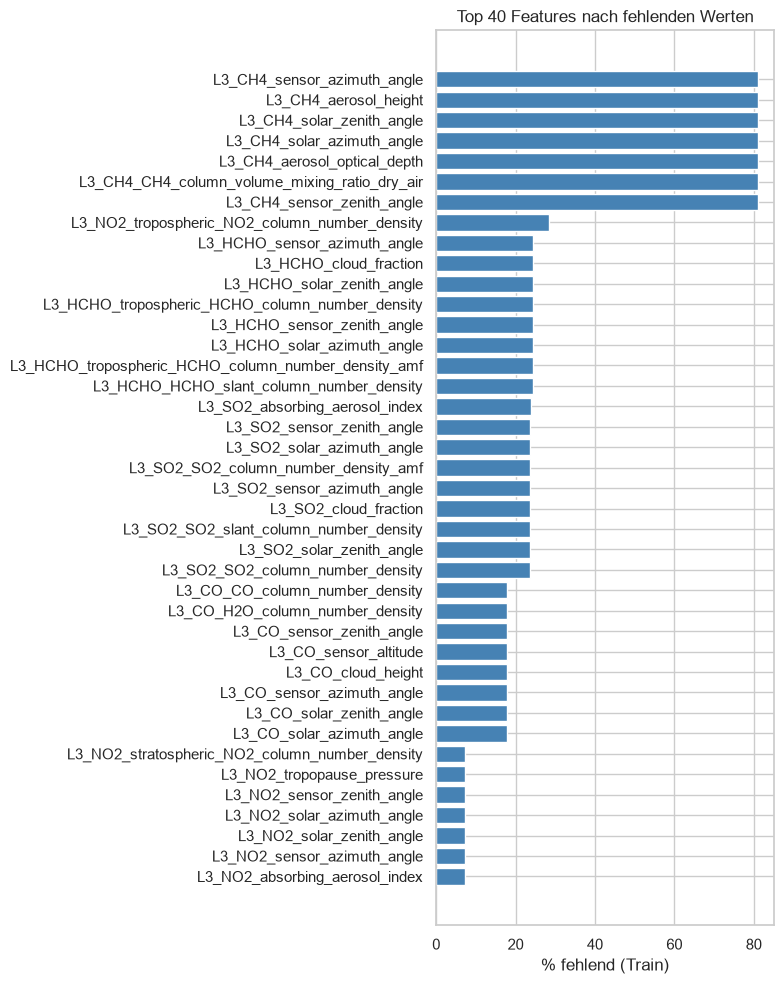

In [4]:
missing = (train[features].isna().mean() * 100).sort_values(ascending=False)

print("Features ohne fehlende Werte:", int((missing == 0).sum()),
      "von", len(features))
fig, ax = plt.subplots(figsize=(8, 10))
top = missing.head(40)
ax.barh(top.index[::-1], top.values[::-1], color="steelblue")
ax.set_xlabel("% fehlend (Train)")
ax.set_title("Top 40 Features nach fehlenden Werten")
plt.tight_layout()
plt.show()

In [5]:
# Anteil fehlender Werte pro Satellitenprodukt (Mittel über dessen Spalten)
prod_missing = pd.DataFrame({
    "train_%": {g: train[[c for c in satellite if c.split("_")[1] == g]]
                .isna().mean().mean() * 100 for g in sat_groups},
    "test_%": {g: test[[c for c in satellite if c.split("_")[1] == g]]
               .isna().mean().mean() * 100 for g in sat_groups},
}).round(1).sort_values("train_%", ascending=False)
prod_missing

,train_%,test_%
CH4,81.0,80.7
HCHO,24.3,26.2
SO2,23.7,25.9
CO,17.7,18.6
NO2,8.9,10.1
CLOUD,3.3,3.9
O3,0.9,1.3
AER,0.6,0.6


Die Wetter-Features sind vollständig. Satelliten-Features haben Lücken
(Wolken, Orbitabdeckung); bei CH4 fehlen etwa 81 % der Werte. Die Lücken sind
in Train und Test ähnlich, daher sind Imputation oder Baummodelle, die `NaN`
verarbeiten, gut geeignet.

## 3. Target: tägliches PM2.5

count    30557.00
mean        61.15
std         46.86
min          1.00
25%         25.00
50%         50.00
75%         80.00
max        815.00
Name: target, dtype: float64
Schiefe: 2.04
Werte <= 0: 0


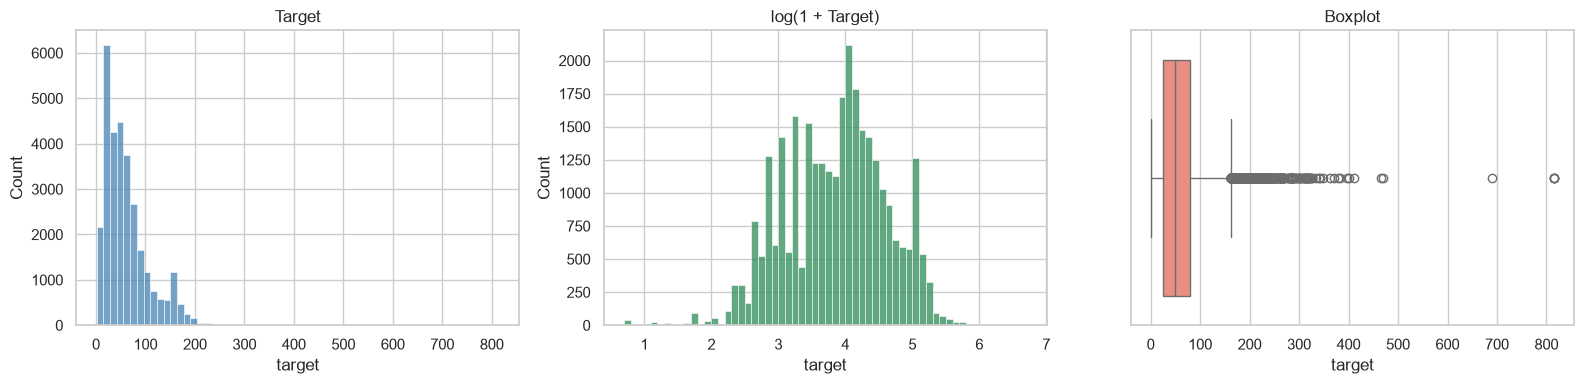

In [6]:
print(train[target].describe().round(2))
print("Schiefe:", round(train[target].skew(), 2))
print("Werte <= 0:", int((train[target] <= 0).sum()))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(train[target], bins=60, ax=axes[0], color="steelblue")
axes[0].set_title("Target")
sns.histplot(np.log1p(train[target]), bins=60, ax=axes[1], color="seagreen")
axes[1].set_title("log(1 + Target)")
sns.boxplot(x=train[target], ax=axes[2], color="salmon")
axes[2].set_title("Boxplot")
plt.tight_layout()
plt.show()

In [7]:
q = train[target].quantile([0.5, 0.9, 0.95, 0.99, 0.999]).round(1)
print(q.to_string())
print("Zeilen über 200:", int((train[target] > 200).sum()))

0.500     50.0
0.900    132.0
0.950    158.0
0.990    198.0
0.999    311.9
Zeilen über 200: 256


Das Target ist rechtsschief mit einem langen Ausläufer an Belastungsspitzen
(Maximum 815 µg/m³). Eine Log-Transformation macht die Verteilung annähernd
symmetrisch. Da der RMSE auf der Originalskala berechnet wird, dominieren
wenige Extremwerte den Fehler. Wir müssen bewusst entscheiden, ob wir sie
behalten, kappen oder gesondert modellieren (Meilenstein 3).

## 4. Zeit

Train: 2020-01-02 bis 2020-04-04
Test:  2020-01-02 bis 2020-04-04


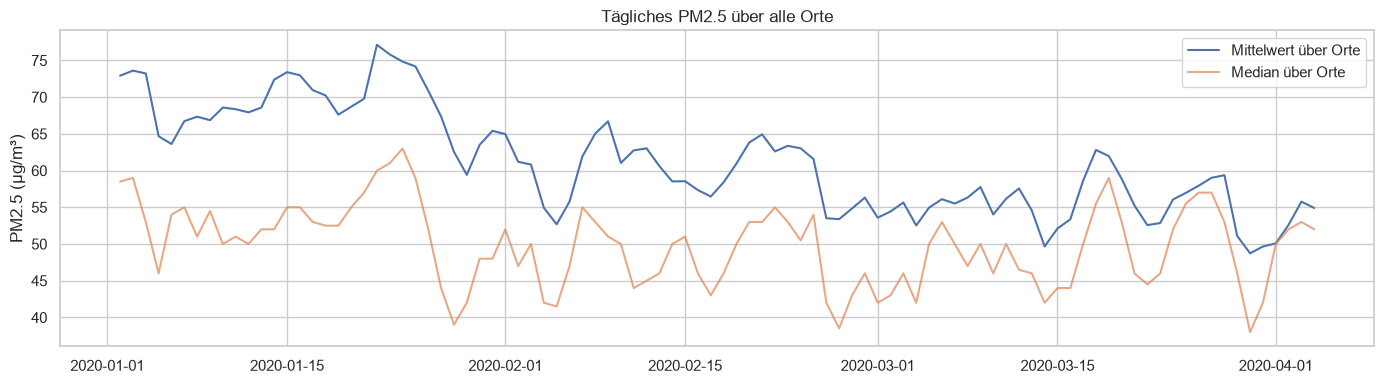

In [8]:
print("Train:", train.Date.min().date(), "bis", train.Date.max().date())
print("Test: ", test.Date.min().date(), "bis", test.Date.max().date())

daily = train.groupby("Date")[target].agg(["mean", "median", "count"])
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily.index, daily["mean"], label="Mittelwert über Orte")
ax.plot(daily.index, daily["median"], label="Median über Orte", alpha=0.7)
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Tägliches PM2.5 über alle Orte")
ax.legend()
plt.tight_layout()
plt.show()

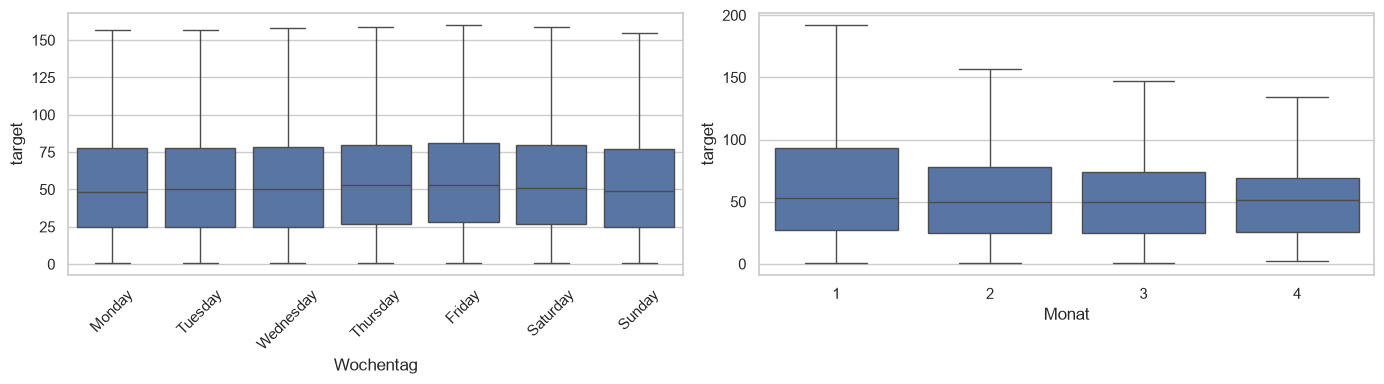

In [9]:
train["weekday"] = train["Date"].dt.day_name()
train["month"] = train["Date"].dt.month
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday",
         "Sunday"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=train, x="weekday", y=target, order=order, ax=axes[0],
            showfliers=False)
axes[0].set_xlabel("Wochentag")
axes[0].tick_params(axis="x", rotation=45)
sns.boxplot(data=train, x="month", y=target, ax=axes[1], showfliers=False)
axes[1].set_xlabel("Monat")
plt.tight_layout()
plt.show()

Train und Test decken **denselben Zeitraum** ab (2. Jan bis 4. Apr 2020), der
Split ist also kein Zeit-Split. Die Belastung ändert sich von Tag zu Tag an
vielen Orten gleichzeitig (gemeinsames Wetter), daher können Datumsinformationen
nützlich sein.

## 5. Orte

In [10]:
tr_places, te_places = set(train.Place_ID), set(test.Place_ID)
print("Orte Train:", len(tr_places), "| Test:", len(te_places),
      "| Überschneidung:", len(tr_places & te_places))

per_place = train.groupby("Place_ID")[target].agg(
    ["mean", "std", "min", "max", "count"])
print(per_place["count"].describe().round(1))

Orte Train: 340 | Test: 179 | Überschneidung: 0
count    340.0
mean      89.9
std       12.0
min        3.0
25%       92.0
50%       94.0
75%       94.0
max       94.0
Name: count, dtype: float64


Train und Test enthalten **komplett verschiedene Orte**. Das Modell muss auf
unbekannte Orte verallgemeinern, daher muss die Validierung nach `Place_ID`
gruppiert erfolgen (z. B. `GroupKFold`). Ein zufälliger Split würde Ortsidentität
durchsickern lassen und zu zu optimistischen Scores führen.

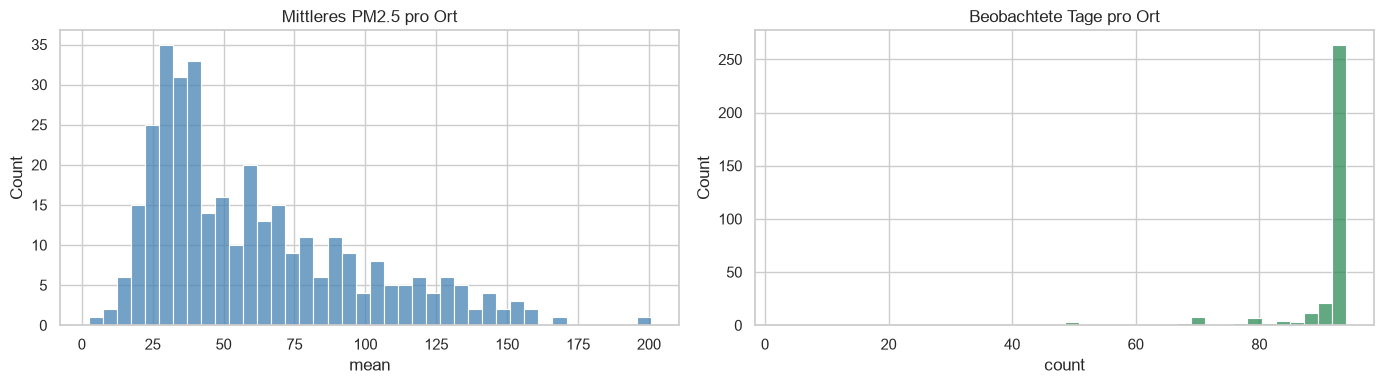

Anteil der Varianz, der durch den Orts-Mittelwert erklärt wird: 62.0%


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(per_place["mean"], bins=40, ax=axes[0], color="steelblue")
axes[0].set_title("Mittleres PM2.5 pro Ort")
sns.histplot(per_place["count"], bins=40, ax=axes[1], color="seagreen")
axes[1].set_title("Beobachtete Tage pro Ort")
plt.tight_layout()
plt.show()

# Wie viel Varianz liegt zwischen Orten und wie viel innerhalb eines Ortes?
total_var = train[target].var()
between = train.groupby("Place_ID")[target].transform("mean").var()
print(f"Anteil der Varianz, der durch den Orts-Mittelwert erklärt wird: "
      f"{between / total_var:.1%}")

Die Ortsidentität erklärt einen großen Teil der Varianz, ist aber für
unbekannte Orte nicht nutzbar. Features, die den Charakter eines Ortes
beschreiben (typisches NO2, Aerosol, Bewölkung), sind der Weg, dieses Wissen zu
übertragen.

## 6. Features und Target

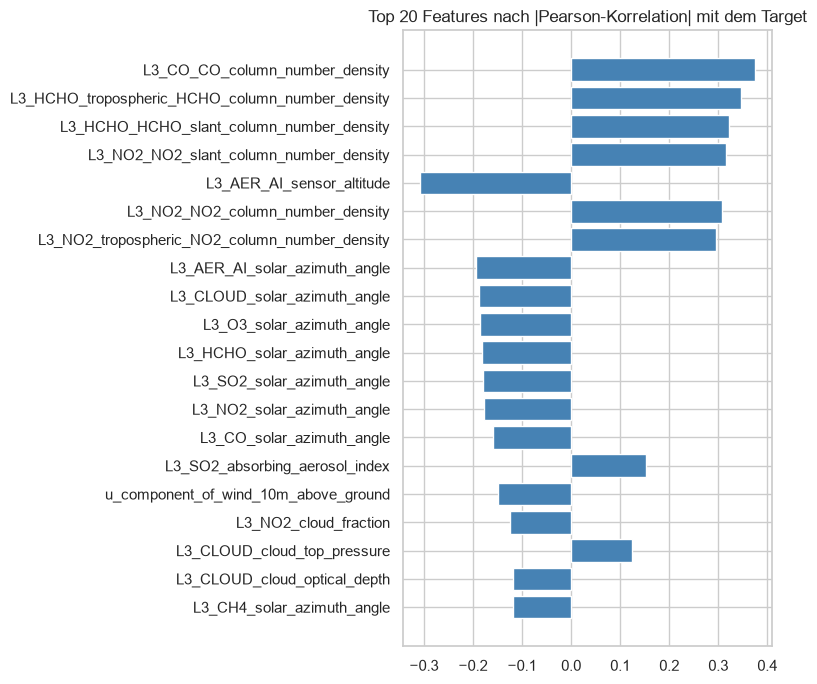

In [12]:
corr = train[features + [target]].corr(numeric_only=True)[target]
corr = corr.drop(target).dropna()
top_corr = corr.reindex(corr.abs().sort_values(ascending=False).index).head(20)

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top_corr.index[::-1], top_corr.values[::-1], color="steelblue")
ax.set_title("Top 20 Features nach |Pearson-Korrelation| mit dem Target")
plt.tight_layout()
plt.show()

In [13]:
# Spearman ist robuster gegenüber dem schiefen Target und Ausreißern
spear = train[features].corrwith(train[target], method="spearman").dropna()
top_sp = spear.reindex(spear.abs().sort_values(ascending=False).index).head(15)
top_sp.round(3)

L3_AER_AI_sensor_altitude                             -0.381
L3_HCHO_tropospheric_HCHO_column_number_density        0.378
L3_HCHO_HCHO_slant_column_number_density               0.362
L3_CO_sensor_altitude                                 -0.359
L3_NO2_tropospheric_NO2_column_number_density          0.358
L3_CO_CO_column_number_density                         0.343
L3_NO2_NO2_column_number_density                       0.324
L3_NO2_sensor_altitude                                -0.283
L3_NO2_NO2_slant_column_number_density                 0.268
L3_CH4_CH4_column_volume_mixing_ratio_dry_air          0.214
u_component_of_wind_10m_above_ground                  -0.191
L3_O3_O3_column_number_density                        -0.178
L3_CLOUD_cloud_optical_depth                          -0.176
L3_NO2_tropopause_pressure                            -0.158
L3_HCHO_tropospheric_HCHO_column_number_density_amf   -0.157
dtype: float64

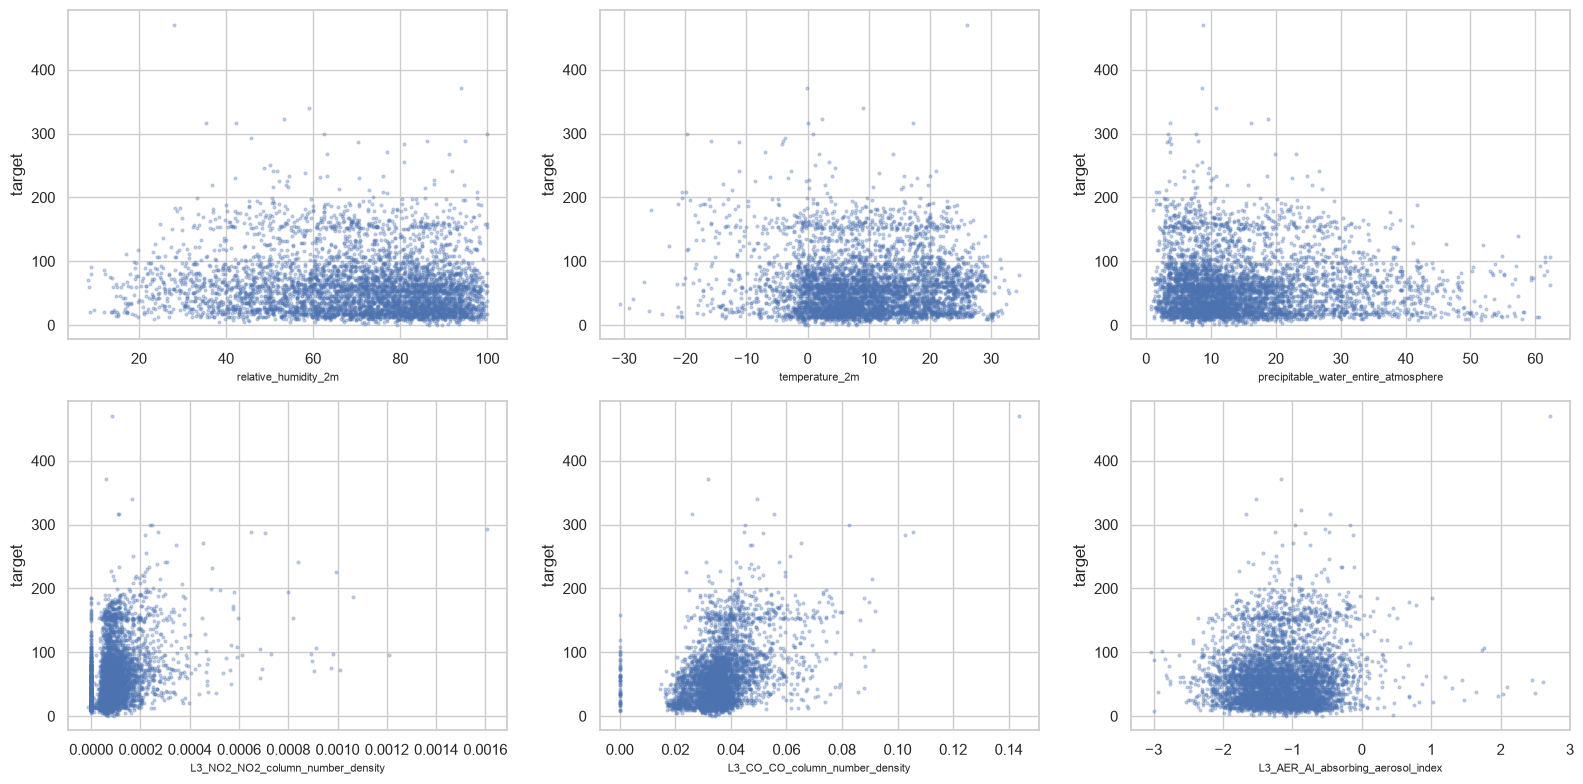

In [14]:
key = ["relative_humidity_2m_above_ground", "temperature_2m_above_ground",
       "precipitable_water_entire_atmosphere",
       "L3_NO2_NO2_column_number_density",
       "L3_CO_CO_column_number_density", "L3_AER_AI_absorbing_aerosol_index"]
sample_df = train.sample(5000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), key):
    ax.scatter(sample_df[col], sample_df[target], s=4, alpha=0.3)
    ax.set_xlabel(col.replace("_above_ground", ""), fontsize=8)
    ax.set_ylabel("target")
plt.tight_layout()
plt.show()

Die einzelnen Korrelationen sind schwach bis mäßig (maximal etwa 0,38): Kein
einzelnes Feature sagt PM2.5 gut voraus. Ein Modell muss viele Features
kombinieren, vermutlich nichtlinear.

### Redundanz zwischen Features

In [15]:
corr_mat = train[features].corr(numeric_only=True).abs()
upper = corr_mat.where(np.triu(np.ones(corr_mat.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)
print("Feature-Paare mit |r| > 0.95:", int((pairs > 0.95).sum()))
pairs.head(10).round(3)

Feature-Paare mit |r| > 0.95: 37


L3_CLOUD_solar_zenith_angle                    L3_AER_AI_solar_zenith_angle      1.000
L3_HCHO_solar_zenith_angle                     L3_SO2_solar_zenith_angle         1.000
L3_CO_solar_zenith_angle                       L3_HCHO_solar_zenith_angle        0.997
                                               L3_SO2_solar_zenith_angle         0.997
L3_CLOUD_sensor_zenith_angle                   L3_AER_AI_sensor_zenith_angle     0.997
L3_CLOUD_sensor_azimuth_angle                  L3_AER_AI_sensor_azimuth_angle    0.995
L3_HCHO_sensor_zenith_angle                    L3_SO2_sensor_zenith_angle        0.995
L3_CLOUD_cloud_base_height                     L3_CLOUD_cloud_top_height         0.993
L3_O3_sensor_azimuth_angle                     L3_CLOUD_sensor_azimuth_angle     0.991
L3_CH4_CH4_column_volume_mixing_ratio_dry_air  L3_CH4_aerosol_height             0.990
dtype: float64

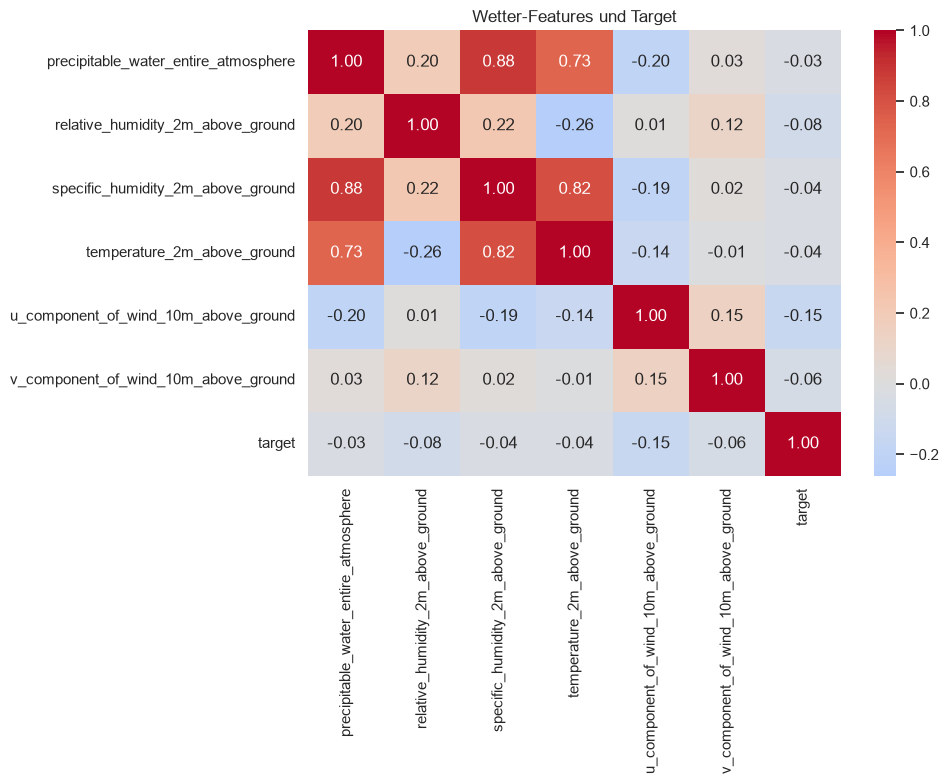

In [16]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(train[weather + [target]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, ax=ax)
ax.set_title("Wetter-Features und Target")
plt.tight_layout()
plt.show()

Viele Satellitenspalten (Sensor- und Sonnenwinkel, je Produkt wiederholt) sind
nahezu Duplikate voneinander. Sie liefern wenig zusätzliche Information und
können für die ersten Modelle auf eine Spalte pro Winkeltyp reduziert werden.

## 7. Verteilung Train vs. Test

In [17]:
# standardisierte Mittelwertdifferenz pro Feature (Test vs. Train)
std = train[features].std().replace(0, np.nan)
smd = ((test[features].mean() - train[features].mean()) / std).dropna()
print("Features mit |standardisierter Mittelwertdifferenz| > 0.2:",
      int((smd.abs() > 0.2).sum()))
smd.abs().sort_values(ascending=False).head(10).round(3)

Features mit |standardisierter Mittelwertdifferenz| > 0.2: 0


L3_AER_AI_solar_zenith_angle                       0.183
L3_CLOUD_solar_zenith_angle                        0.175
L3_HCHO_solar_zenith_angle                         0.173
L3_SO2_solar_zenith_angle                          0.172
L3_CO_solar_zenith_angle                           0.168
L3_SO2_SO2_column_number_density_amf               0.163
L3_O3_solar_zenith_angle                           0.157
L3_HCHO_tropospheric_HCHO_column_number_density    0.148
L3_NO2_tropopause_pressure                         0.145
specific_humidity_2m_above_ground                  0.130
dtype: float64

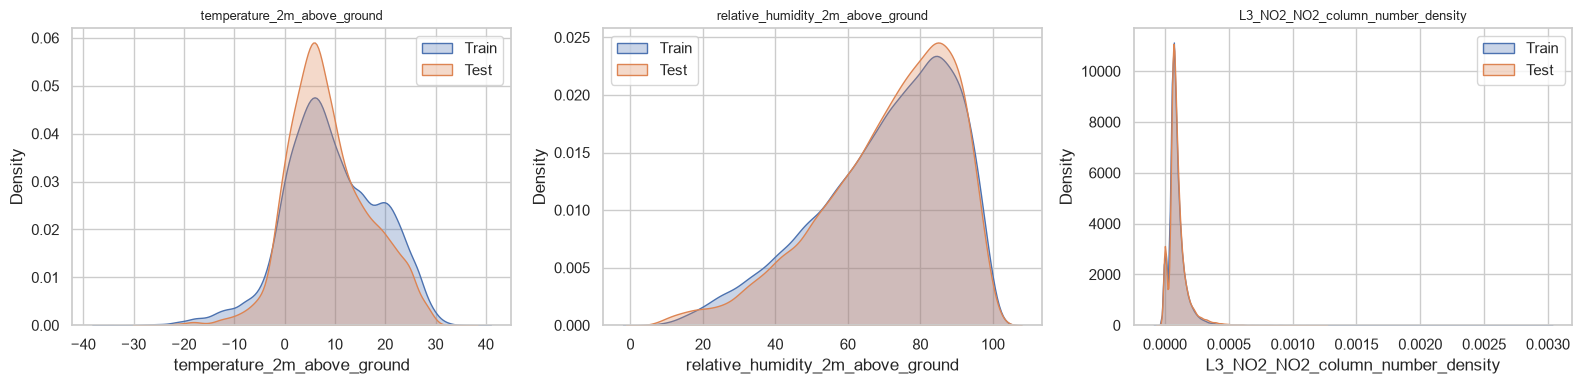

In [18]:
cols = ["temperature_2m_above_ground", "relative_humidity_2m_above_ground",
        "L3_NO2_NO2_column_number_density"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, cols):
    sns.kdeplot(train[col], ax=ax, label="Train", fill=True, alpha=0.3)
    sns.kdeplot(test[col], ax=ax, label="Test", fill=True, alpha=0.3)
    ax.set_title(col, fontsize=9)
    ax.legend()
plt.tight_layout()
plt.show()

Kein Feature hat eine standardisierte Differenz über 0,2: Es gibt keinen
starken Covariate Shift. Der Unterschied zwischen Train und Test liegt in den
*Orten*, nicht in den Wertebereichen der Features.

## 8. Erkenntnisse und nächste Schritte

**Was wir gelernt haben**

1. Das Target ist das tägliche mittlere PM2.5: rechtsschief (Median 50,
   Mittelwert 61, Maximum 815) mit seltenen, sehr hohen Spitzen, die den RMSE
   dominieren werden.
2. Train (30.557 Zeilen, 340 Orte) und Test (16.136 Zeilen, 179 Orte) decken
   dieselben Tage ab, haben aber **disjunkte Orte**. Die Validierung braucht
   `GroupKFold` nach `Place_ID`.
3. `target_min/max/variance/count` gibt es nur in Train: Leakage, ausschließen.
4. Wetterspalten sind vollständig; Satellitenspalten haben Lücken (CH4 etwa
   81 % fehlend), die in Train und Test ähnlich sind.
5. Kein einzelnes Feature korreliert stark mit dem Target. Viele
   Satellitenspalten sind nahezu Duplikate.

**Plan für Meilenstein 2 (Baseline)**

- **Baseline-Modell:** Den globalen (oder datumsbezogenen) Mittelwert des
  Targets vorhersagen. Bewertung mit RMSE über `GroupKFold`.
- Danach: ein baumbasiertes Modell (z. B. Random Forest oder Gradient Boosting)
  auf Wetter- und deduplizierten Satelliten-Features, Datumsfeatures und
  `NaN`-Behandlung.
- `log1p(target)` als Zielgröße prüfen sowie tagesbezogene Aggregate der
  Features über alle Orte als zusätzliches Signal.